# Equidade

Uma regra pode cumprir G1 no total e falhar num subgrupo. Para ver isso, o X5 usa o modelo treinado com as internações
de 2019 a 2021, recalibra a regra no começo de cada ano com o ano anterior e a aplica em 2023, 2024 e 2025, comparando
duas regras. O Mondrian por classe é a regra de todos os outros experimentos, com um corte só para todas as internações;
o Mondrian cruzado calcula um corte por faixa etária, com os óbitos da faixa. A FDL é medida por faixa etária, sexo e
polo, que separa os hospitais de Montes Claros dos outros. Tudo sai de
`reports/exploratorios/morte/nenhuma/resultados_x5.json`, e a figura do fim é `reports/figures/morte/equidade_x5.png`.

In [1]:
import json

import pandas as pd
from IPython.display import Image

from triagem_baixo_risco import config
from triagem_baixo_risco.modeling.predict import exact_ci, holm

EXPLORATORIOS = config.REPORTS_DIR / "exploratorios" / "morte" / "nenhuma"
REGRAS = {"global": "por classe", "cruzado": "cruzado"}
VARIAVEIS = {"faixa_etaria": "faixa etária", "sexo": "sexo", "polo": "polo"}
NIVEIS = {"F": "feminino", "M": "masculino", "True": "Montes Claros", "False": "outros municípios"}


def pct(x, casas=2):
    return f"{100 * x:.{casas}f}%".replace(".", ",")


def num(x, casas=0):
    # 1234567.891 com casas=2 vira "1.234.567,89"
    return f"{x:,.{casas}f}".replace(",", " ").replace(".", ",").replace(" ", ".")


def pv(p):
    return "< 0,0001" if p < 0.0001 else num(p, 4)


linhas = json.loads((EXPLORATORIOS / "resultados_x5.json").read_text())
x5 = pd.DataFrame([{**r, "regra": REGRAS[regra]} for regra, rs in linhas.items() for r in rs])
x5["variável"] = x5["variavel"].map(VARIAVEIS)
x5["nível"] = x5["nivel"].map(lambda v: NIVEIS.get(v, v))


def lado_a_lado(tabela, colunas):
    tabela = tabela.unstack("regra").swaplevel(axis=1)
    return tabela[[(r, c) for r in REGRAS.values() for c in colunas]]

## Por ano

In [2]:
ano_a_ano = pd.DataFrame(
    {
        "FDL": x5["fdl"].map(lambda v: pct(v, 1)) + " (" + x5["fdl_k"].map(num) + " de " + x5["fdl_n"].map(num) + ")",
        "p G1": x5["p_g1"].map(pv),
        "liberadas": x5["fracao_liberada"].map(lambda v: pct(v, 1)),
    }
).set_index([x5["variável"], x5["nível"], x5["ano"], x5["regra"]])
ano_a_ano = lado_a_lado(ano_a_ano, ["FDL", "p G1", "liberadas"])
ano_a_ano.loc["faixa etária"]

regra               por classe                                  cruzado  \
                           FDL      p G1 liberadas                  FDL   
nível ano                                                                 
0-17  2023   31,7% (63 de 199)  < 0,0001     86,3%      2,0% (4 de 199)   
      2024   26,4% (51 de 193)  < 0,0001     86,4%      3,6% (7 de 193)   
      2025   17,5% (28 de 160)  < 0,0001     84,9%      3,8% (6 de 160)   
18-39 2023   26,6% (75 de 282)  < 0,0001     92,0%      2,1% (6 de 282)   
      2024   23,2% (69 de 297)  < 0,0001     90,5%     5,7% (17 de 297)   
      2025   15,6% (47 de 302)  < 0,0001     88,5%      1,7% (5 de 302)   
40-59 2023    8,4% (80 de 951)    0,0001     65,7%     3,9% (37 de 951)   
      2024  8,4% (86 de 1.021)  < 0,0001     64,8%   5,7% (58 de 1.021)   
      2025  5,9% (60 de 1.025)    0,1529     61,1%   5,4% (55 de 1.025)   
60-79 2023  4,0% (88 de 2.200)    0,9533     35,1%  6,1% (135 de 2.200)   
      2024  3,2% (72 de 2.216)    0,9990     37,7%  4,6% (101 de 2.216)   
      2025  2,0% (48 de 2.345)    1,0000     35,6%   4,2% (98 de 2.345)   
80+   2023  0,8% (14 de 1.851)    1,0000      8,4%   3,6% (66 de 1.851)   
      2024  1,0% (20 de 1.921)    1,0000      9,9%   5,0% (97 de 1.921)   
      2025  0,6% (11 de 1.852)    1,0000      9,3%   5,1% (95 de 1.852)   

regra                         
              p G1 liberadas  
nível ano                     
0-17  2023  0,8902     54,1%  
      2024  0,6643     61,8%  
      2025  0,6621     67,7%  
18-39 2023  0,9198     63,2%  
      2024  0,2859     74,3%  
      2025  0,9732     63,9%  
40-59 2023  0,7859     57,9%  
      2024  0,2842     61,0%  
      2025  0,3318     59,4%  
60-79 2023  0,0778     40,3%  
      2024  0,6899     41,6%  
      2025  0,8397     41,4%  
80+   2023  0,9495     19,7%  
      2024  0,4710     24,3%  
      2025  0,4139     22,5%

Com um corte só, a regra libera demais os óbitos de jovens. Em 2023, 31,7% dos óbitos de 0 a 17 anos e 26,6% dos de 18 a
39 foram liberados, contra 0,8% dos de 80 anos ou mais. A diferença diminuiu até 2025, mas ainda ficou em 17,5% e 15,6%
nas duas faixas jovens. O corte é escolhido pelos óbitos de todas as idades, e os óbitos de jovens, com risco previsto
baixo, ficam do lado liberado com muito mais frequência.

O cruzado traz as faixas para perto de 5% e muda quem é liberado. De 0 a 17 anos, a fração liberada cai de 86,3% para
54,1% em 2023; de 80 anos ou mais, sobe de 8,4% para 19,7%.

In [3]:
cruzado = x5[(x5["regra"] == "cruzado") & (x5["variavel"] == "faixa_etaria")]
menor = cruzado.loc[cruzado["p_g1"].idxmin()]
ajustado = min(holm(cruzado["p_g1"])["p_adjusted"])
print(f"menor p de G1 no cruzado: {pv(menor['p_g1'])} ({menor['nível']}, {menor['ano']})")
print(f"menor p depois de Holm entre as {len(cruzado)} combinações de faixa e ano: {pv(ajustado)}")

menor p de G1 no cruzado: 0,0778 (60-79, 2023)
menor p depois de Holm entre as 15 combinações de faixa e ano: 1,0000


Nenhuma combinação de faixa e ano viola G1 no cruzado: o menor p, 0,0778, dos 60 a 79 anos em 2023, vai a 1 depois de
Holm. Por isso H5 não é refutada nos exploratórios.

In [4]:
ano_a_ano.loc[["sexo", "polo"]]

regra                                     por classe                    \
                                                 FDL    p G1 liberadas   
variável nível             ano                                           
sexo     feminino          2023  5,8% (146 de 2.525)  0,1064     72,2%   
                           2024  4,7% (122 de 2.570)  0,6627     71,3%   
                           2025   3,4% (88 de 2.592)  0,9984     68,6%   
         masculino         2023  5,9% (174 de 2.958)  0,0726     56,5%   
                           2024  5,7% (176 de 3.078)  0,1084     56,2%   
                           2025  3,4% (106 de 3.092)  0,9987     52,9%   
polo     Montes Claros     2023  5,7% (132 de 2.308)  0,1312     61,5%   
                           2024  4,6% (122 de 2.629)  0,7281     62,6%   
                           2025   2,9% (79 de 2.734)  1,0000     59,7%   
         outros municípios 2023  5,9% (188 de 3.175)  0,0613     67,8%   
                           2024  5,8% (176 de 3.019)  0,0791     66,1%   
                           2025  3,9% (115 de 2.950)  0,9790     62,9%   

regra                                        cruzado                    
                                                 FDL    p G1 liberadas  
variável nível             ano                                          
sexo     feminino          2023  5,1% (128 de 2.525)  0,3819     59,5%  
                           2024  4,8% (124 de 2.570)  0,5883     65,1%  
                           2025  5,2% (135 de 2.592)  0,3177     61,5%  
         masculino         2023  4,1% (120 de 2.958)  0,9309     41,5%  
                           2024  5,1% (156 de 3.078)  0,4160     47,6%  
                           2025  4,0% (124 de 3.092)  0,9538     45,0%  
polo     Montes Claros     2023   3,2% (75 de 2.308)  0,9980     47,3%  
                           2024   3,1% (81 de 2.629)  0,9998     54,6%  
                           2025   2,9% (78 de 2.734)  1,0000     50,8%  
         outros municípios 2023  5,4% (173 de 3.175)  0,1674     54,3%  
                           2024  6,6% (199 de 3.019)  0,0042     59,3%  
                           2025  6,1% (181 de 2.950)  0,0220     56,5%

Por sexo, a FDL fica parecida nas duas regras, entre 3,4% e 5,9%. O polo não. No cruzado, os hospitais fora de Montes
Claros tiveram FDL de 6,6% em 2024 e de 6,1% em 2025, com p de 0,0042 e 0,0220, enquanto os de Montes Claros ficaram
entre 2,9% e 3,2%. Nenhuma hipótese testa o polo, mas o corte por faixa etária não garante nada por região, e esse
resultado vai para a discussão.

## De 2023 a 2025 somados

In [5]:
soma = (
    x5.assign(liberadas=x5["fracao_liberada"] * x5["n"])
    .groupby(["variável", "nível", "regra"])[["fdl_k", "fdl_n", "liberadas", "n"]]
    .sum()
)
ic = [exact_ci(k, n) for k, n in zip(soma["fdl_k"], soma["fdl_n"])]
somados = pd.DataFrame(
    {
        "óbitos liberados": soma["fdl_k"].map(num) + " de " + soma["fdl_n"].map(num),
        "FDL": (soma["fdl_k"] / soma["fdl_n"]).map(lambda v: pct(v, 1)),
        "IC de 95%": [f"{pct(lo, 1)} a {pct(hi, 1)}" for lo, hi in ic],
        "liberadas": (soma["liberadas"] / soma["n"]).map(lambda v: pct(v, 1)),
    },
    index=soma.index,
)
lado_a_lado(somados, ["FDL", "IC de 95%", "liberadas"])

regra                          por classe                          cruzado  \
                                      FDL      IC de 95% liberadas     FDL   
variável     nível                                                           
faixa etária 0-17                   25,7%  22,1% a 29,6%     85,8%    3,1%   
             18-39                  21,7%  19,0% a 24,6%     90,3%    3,2%   
             40-59                   7,5%    6,6% a 8,5%     63,7%    5,0%   
             60-79                   3,1%    2,7% a 3,5%     36,1%    4,9%   
             80+                     0,8%    0,6% a 1,1%      9,2%    4,6%   
polo         Montes Claros           4,3%    3,9% a 4,8%     61,2%    3,1%   
             outros municípios       5,2%    4,8% a 5,7%     65,6%    6,0%   
sexo         feminino                4,6%    4,2% a 5,1%     70,7%    5,0%   
             masculino               5,0%    4,6% a 5,5%     55,1%    4,4%   

regra                                                  
                                  IC de 95% liberadas  
variável     nível                                     
faixa etária 0-17               1,8% a 4,9%     61,4%  
             18-39              2,1% a 4,6%     67,3%  
             40-59              4,3% a 5,8%     59,5%  
             60-79              4,4% a 5,5%     41,2%  
             80+                4,1% a 5,2%     22,3%  
polo         Montes Claros      2,7% a 3,5%     51,1%  
             outros municípios  5,6% a 6,6%     56,8%  
sexo         feminino           4,6% a 5,5%     62,1%  
             masculino          4,0% a 4,8%     44,8%

Nos três anos somados, o Mondrian por classe liberou 25,7% dos óbitos de 0 a 17 anos, com IC de 22,1% a 29,6%, e 0,8%
dos de 80 anos ou mais. No cruzado, as faixas vão de 3,1% a 5,0%, e o custo aparece na fração liberada das faixas
jovens: de 85,8% para 61,4% das internações de 0 a 17 anos e de 90,3% para 67,3% das de 18 a 39. A figura mostra as
mesmas FDL por faixa, com o IC exato e a linha de 5%.

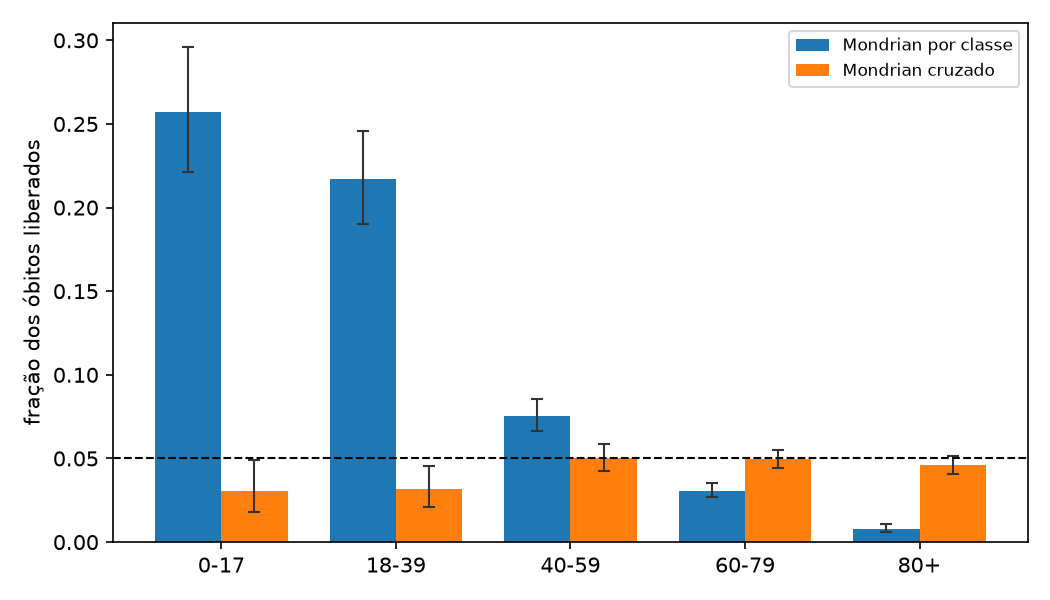

In [6]:
Image(filename=config.FIGURES_DIR / "morte" / "equidade_x5.png")